## Предсказание ишемической болезни сердца по демографическим и медицинским показателям человека (логистическая регрессия)

Импорт библиотек и загрузка датасета:

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.metrics as sklmetr
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [2]:
disease_data = pd.read_csv('heart_disease.csv')
disease_data.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
disease_data.shape

(4238, 16)

In [4]:
disease_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [5]:
disease_data.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


### Чистка датасета

In [6]:
print(f"Число дубликатов: {disease_data[disease_data.duplicated()].shape[0]}")

Число дубликатов: 0


Удалим столбец Education - в описании датасета про него ничего не сказано, так что непонятно как его интерпретировать:

In [7]:
disease_data = disease_data.drop(['education'], axis=1)
disease_data.head()

,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [8]:
disease_data.isna().sum()

,0
male,0
age,0
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50
sysBP,0


Для столбцов с малым количеством пропущенных значений (около 50 или меньше), удалим записи с пропущенными значениями:

In [9]:
disease_data = disease_data.dropna(subset=['heartRate', 'BMI', 'cigsPerDay', 'totChol', 'BPMeds'])
disease_data.isna().sum()

,0
male,0
age,0
currentSmoker,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,0
sysBP,0


Для признака glucose заполним пропуски медианой/средним при делении на train/test. Для начала посмотрим как распределены значения признака:

<Axes: xlabel='glucose', ylabel='Count'>

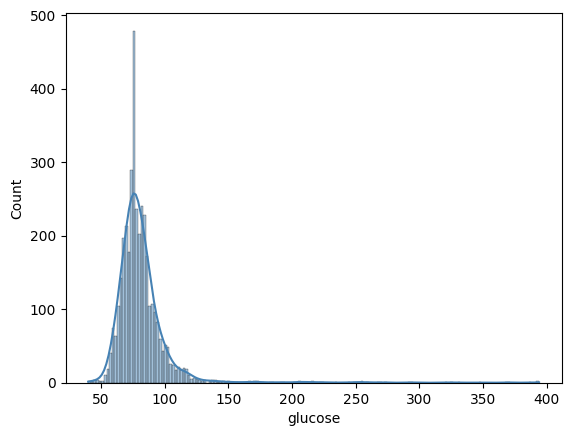

In [10]:
sns.histplot(disease_data['glucose'].dropna(), kde=True, color='steelblue')

### EDA

<Axes: >

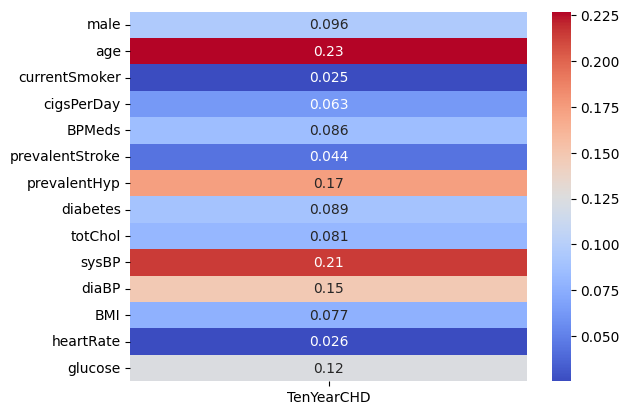

In [13]:
corr_matrix = disease_data.corr()
sns.heatmap(corr_matrix['TenYearCHD'].drop('TenYearCHD').to_frame(), annot=True, cmap='coolwarm')

In [14]:
disease_data[['TenYearCHD']].value_counts()

,count
TenYearCHD,
0,3477
1,611


### Эксперимент А (Логистическая регрессия для одного параметра)  

Для первого эксперимента возьмём признак с наибольшей корреляцией - возраст, поскольку по предыдущему пункту заметен явный дисбаланс классов, установим class_weight='balanced' для логистической регрессии:

In [15]:
xA = disease_data[['age']]
yA = disease_data['TenYearCHD']

In [16]:
xA_train, xA_test, yA_train, yA_test = train_test_split(xA, yA, test_size=0.20, random_state=0)
print(xA_train.shape)
print(xA_test.shape)
print(yA_train.shape)
print(yA_test.shape)

(3270, 1)
(818, 1)
(3270,)
(818,)


In [17]:
expA = LogisticRegression(random_state=0, max_iter=1000, class_weight='balanced').fit(xA_train, yA_train)
yA_pred = expA.predict(xA_test)
yA_pred

array([0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,

In [18]:
comparison = pd.DataFrame({
    "Реальные значения": yA_test.values,
    "Предсказания": yA_pred
})
print(comparison.head(10))

   Реальные значения  Предсказания
0                  0             0
1                  0             0
2                  0             0
3                  0             0
4                  0             0
5                  0             1
6                  0             1
7                  0             0
8                  0             0
9                  0             0


Оценки качества модели:

In [19]:
maeA = sklmetr.mean_absolute_error(yA_test,yA_pred)
mseA = sklmetr.mean_squared_error(yA_test,yA_pred)
r2A = sklmetr.r2_score(yA_test, yA_pred)
print('MAE:', maeA)
print('MSE:', mseA)
print("R^2:", r2A)

MAE: 0.363080684596577
MSE: 0.363080684596577
R^2: -1.8231151808124944


В данном случае метрики MAE, MSE и R^2 выдают такой плохой результат, потому что не подходят для логистической регрессии, воспользуемся более подходящими метриками:

In [20]:
accuracyA = sklmetr.accuracy_score(yA_test, yA_pred)
precisionA = sklmetr.precision_score(yA_test, yA_pred)
recallA = sklmetr.recall_score(yA_test, yA_pred)
print('Accuracy:', accuracyA)
print('Precision:', precisionA)
print('Recall:', recallA)

Accuracy: 0.636919315403423
Precision: 0.23708206686930092
Recall: 0.6290322580645161


### Эксперимент B (Логистическая регрессия для двух параметров)  

Тут возьмём в качестве признаков возраст и систолическое давление:

In [21]:
xB = disease_data[['age', 'sysBP']]
yB = disease_data['TenYearCHD']

In [22]:
xB_train, xB_test, yB_train, yB_test = train_test_split(xB, yB, test_size=0.20, random_state=0)
print(xB_train.shape)
print(xB_test.shape)
print(yB_train.shape)
print(yB_test.shape)

(3270, 2)
(818, 2)
(3270,)
(818,)


In [23]:
expB = LogisticRegression(random_state=0, max_iter=1000, class_weight='balanced').fit(xB_train, yB_train)
yB_pred = expB.predict(xB_test)
yB_pred

array([0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,

In [24]:
comparison = pd.DataFrame({
    "Реальные значения": yB_test.values,
    "Предсказания": yB_pred
})
print(comparison.head(10))

   Реальные значения  Предсказания
0                  0             0
1                  0             0
2                  0             0
3                  0             0
4                  0             1
5                  0             1
6                  0             1
7                  0             0
8                  0             0
9                  0             0


Оценки качества модели:

In [25]:
maeB = sklmetr.mean_absolute_error(yB_test,yB_pred)
mseB = sklmetr.mean_squared_error(yB_test,yB_pred)
r2B = sklmetr.r2_score(yB_test, yB_pred)
print('MAE:', maeB)
print('MSE:', mseB)
print("R^2:", r2B)

MAE: 0.33985330073349634
MSE: 0.33985330073349634
R^2: -1.6425118527470488


Аналогично оценим метриками более соответствующими логистической регрессии:

In [26]:
accuracyB = sklmetr.accuracy_score(yB_test, yB_pred)
precisionB = sklmetr.precision_score(yB_test, yB_pred)
recallB = sklmetr.recall_score(yB_test, yB_pred)
print('Accuracy:', accuracyB)
print('Precision:', precisionB)
print('Recall:', recallB)

Accuracy: 0.6601466992665037
Precision: 0.24503311258278146
Recall: 0.5967741935483871


### Эксперимент С (Логистическая регрессия на основе всех возможных признаков)  

In [32]:
xC = disease_data.iloc[:, :-1]
yC = disease_data.iloc[:, -1]

In [33]:
xC_train, xC_test, yC_train, yC_test = train_test_split(xC, yC, test_size=0.20, random_state=0)
xC_train['glucose'] =xC_train['glucose'].fillna(xC_train['glucose'].median())
xC_test['glucose'] =xC_test['glucose'].fillna(xC_train['glucose'].median())
print(xC_train.shape)
print(xC_test.shape)
print(yC_train.shape)
print(yC_test.shape)

(3270, 14)
(818, 14)
(3270,)
(818,)


In [34]:
expC = LogisticRegression(random_state=0, max_iter=2000, class_weight='balanced').fit(xC_train, yC_train)
yC_pred = expC.predict(xC_test)
yC_pred

array([1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,

In [35]:
comparison = pd.DataFrame({
    "Реальные значения": yC_test,
    "Предсказания": yC_pred
})
print(comparison.head(10))

      Реальные значения  Предсказания
972                   0             1
3305                  0             0
1756                  0             0
2026                  0             0
3509                  0             1
3325                  0             1
3602                  0             1
3064                  0             0
3696                  0             0
3197                  0             0


Оценки качества модели:

In [36]:
maeC = sklmetr.mean_absolute_error(yC_test,yC_pred)
mseC = sklmetr.mean_squared_error(yC_test,yC_pred)
r2C = sklmetr.r2_score(yC_test, yC_pred)
print('MAE:', maeC)
print('MSE:', mseC)
print("R^2:", r2C)

MAE: 0.3141809290953545
MSE: 0.3141809290953545
R^2: -1.442897648043135


Аналогично оценим метриками более соответствующими логистической регрессии:

In [37]:
accuracyC = sklmetr.accuracy_score(yC_test, yC_pred)
precisionC = sklmetr.precision_score(yC_test, yC_pred)
recallC = sklmetr.recall_score(yC_test, yC_pred)
print('Accuracy:', accuracyC)
print('Precision:', precisionC)
print('Recall:', recallC)

Accuracy: 0.6858190709046454
Precision: 0.28052805280528054
Recall: 0.6854838709677419


Я заметила, что без 'balanced' acurracy было бы больше, но при этом возрастает (до 94%) ошибка 2 рода, что нежелательно для данной задачи:

In [38]:
expCNoBalance = LogisticRegression(random_state=0, max_iter=2000).fit(xC_train, yC_train)
yNB_pred = expCNoBalance.predict(xC_test)

In [39]:
accuracyNB = sklmetr.accuracy_score(yC_test, yNB_pred)
precisionNB = sklmetr.precision_score(yC_test, yNB_pred)
recallNB = sklmetr.recall_score(yC_test, yNB_pred)
print('Accuracy:', accuracyNB)
print('Precision:', precisionNB)
print('Recall:', recallNB)

Accuracy: 0.8545232273838631
Precision: 0.7777777777777778
Recall: 0.056451612903225805
